# Ejercicio 4.a - Distancia de Enzo a la línea del arco

In [1]:
from matplotlib import pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import alc
import ejercicio3
import ejercicio4

filepath_base = '../template-alumnos/futbol'
img = mpimg.imread(f'{filepath_base}/test-gol-enzo.png')

## Puntos de referencia
Coordenadas en la cancha (m) y en la foto (px). Están definidos en `ejercicio4.py`.

In [2]:
objPts = ejercicio4.objPts
imgPts = ejercicio4.imgPts
print(objPts)
print(imgPts)

[[ 0.   30.34]
 [ 0.   37.66]
 [ 5.5  24.84]
 [ 5.5  43.16]
 [11.   34.  ]
 [16.5  26.69]
 [16.5  41.31]]
[[388.  176. ]
 [652.  184.5]
 [157.  231. ]
 [867.  250. ]
 [511.  317. ]
 [146.  406. ]
 [851.  422. ]]


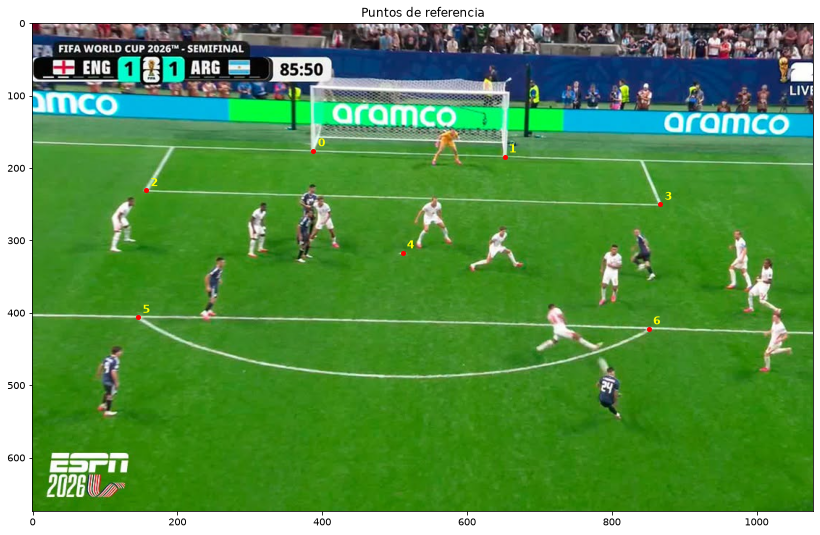

In [3]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(imgPts[:, 0], imgPts[:, 1], 'ro', markersize=4)
for i in range(imgPts.shape[0]):
    plt.text(imgPts[i, 0] + 6, imgPts[i, 1] - 6, str(i), color='yellow', fontsize=11, weight='bold')
plt.title('Puntos de referencia')
plt.show()

## Homografía H (cancha -> imagen) y su inversa

In [4]:
H = ejercicio3.resolverDLT2D(imgPts, objPts)
H_inv = alc.inversa(H)
print(H / H[2, 2])

[[-9.53430550e+00  3.75647487e+01 -7.34465083e+02]
 [ 7.85950332e+00  1.32071508e+00  1.41846387e+02]
 [-1.67225453e-02  1.23844469e-03  1.00000000e+00]]


## Validación
Proyectamos el área chica. Sus esquinas sobre la línea de meta, (0, 24.84) y (0, 43.16), no se usaron para estimar H.

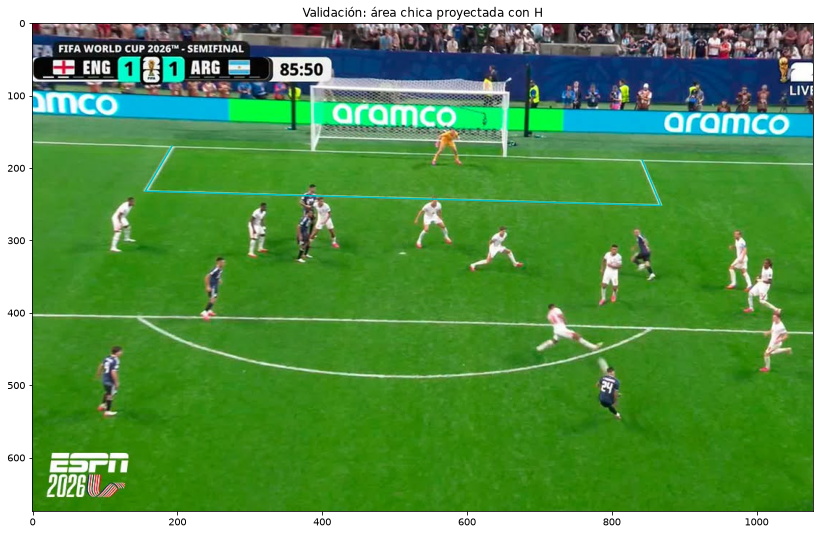

In [5]:
area_chica = ejercicio4.aplicarHomografia(H, np.array([[0.0, 24.84], [5.5, 24.84], [5.5, 43.16], [0.0, 43.16]]))

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(area_chica[:, 0], area_chica[:, 1], 'c-', linewidth=1.5)
plt.title('Validación: área chica proyectada con H')
plt.show()

## Posición de Enzo y distancia a la línea del arco

In [6]:
pie_enzo_img = ejercicio4.pie_enzo_img
U_enzo, V_enzo = ejercicio4.aplicarHomografia(H_inv, pie_enzo_img)[0]
distancia = np.abs(U_enzo)
print(f'Enzo en la cancha: U = {U_enzo:.2f} m, V = {V_enzo:.2f} m')
print(f'Distancia a la línea del arco: {distancia:.2f} m')

Enzo en la cancha: U = 22.24 m, V = 39.80 m
Distancia a la línea del arco: 22.24 m


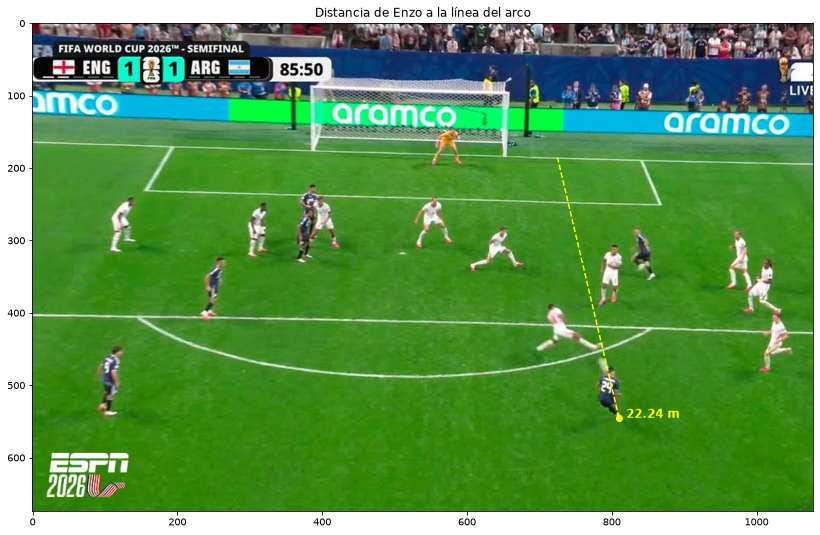

In [7]:
# Segmento perpendicular a la línea de meta, de Enzo a (0, V_enzo), proyectado a la foto
segmento = ejercicio4.aplicarHomografia(H, np.array([[U_enzo, V_enzo], [0.0, V_enzo]]))

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(pie_enzo_img[0, 0], pie_enzo_img[0, 1], 'o', color='yellow', markersize=6)
plt.plot(segmento[:, 0], segmento[:, 1], '--', color='yellow', linewidth=1.5)
plt.text(pie_enzo_img[0, 0] + 10, pie_enzo_img[0, 1], f'{distancia:.2f} m', color='yellow', fontsize=12, weight='bold')
plt.title('Distancia de Enzo a la línea del arco')
plt.show()

## Dudas a consultar
1. **¿Distancia a la línea de meta o al arco?** El enunciado pide la distancia de Enzo a la "línea del arco". Interpretamos que se refiere a la **línea de meta** (la línea de fondo de la cancha, $U = 0$), y por eso calculamos la distancia perpendicular a esa línea: $d = |U| \approx 22.24$ m. ¿Es correcta esta interpretación, o se busca la distancia al **arco** en sí? No es lo mismo, porque Enzo no está enfrente del centro del arco: está corrido unos $5.8$ m hacia un costado ($V \approx 39.80$ contra $V = 34$ del centro).

2. **¿Está bien usar el radio de la medialuna (9.15 m)?** Los puntos 5 y 6 (cortes de la medialuna con la línea del área) usan el radio de $9.15$ m, que no figura como número en el plano: lo tomamos del reglamento (IFAB, Regla 1). Es consistente con lo dibujado en el plano, donde la medialuna llega hasta $U \approx 20$ y el círculo central tiene radio $\approx 9.2$. Los usamos para reducir el error: son los puntos de referencia más cercanos a Enzo, y sin ellos la posición de Enzo se obtiene extrapolando $\mathbf{H}$ fuera de la zona que cubren los demás puntos. Comparando contra la línea real del área grande ($U = 16.5$), sin estos puntos el error en esa zona era de unos $0.5$ m, y con ellos baja a menos de $0.1$ m. ¿Es válido usar este dato, o hay que limitarse a medidas que estén explícitas en el plano?